In [57]:
# """
# Vorbereitung

# 1) mit Excel Station finden, die nahe liegt  C:\Users\CasparGross\Documents\Wetterdaten für Rasmus
# 2) Wetterdaten herungerladen:
# https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/hourly/solar/
# - Solar und air_temperature

# step 1) erstmal Dateien extrahieren
# step 2) manuell in VS txt-format in csv umwandeln (einfach mit rechtsklick + rename)

# 3) Input Dateien in nächster Zeile auswählen/angeben

# 4) Metadaten in den CSV-Dateien anpassen (aus letzte Zelle) !!! hier sehr aufpassen, dass man richtige Metadaten übernimmt!!!


# Anmerkungen zu dfs:

# """


In [58]:

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

base_path_tamb = r"C:\git\github\work_things_at_Kraftwerk\Wetterzeitreihen\DWD_tamb"
base_path_GHI = r"C:\git\github\work_things_at_Kraftwerk\Wetterzeitreihen\DWD_GHI_DHI"


# Inputs und Auswahl des Jahres
name_GHI = 'produkt_st_stunde_20080701_20251231_04393_SanktPO.csv'
name_tamb = 'produkt_tu_stunde_20240815_20260215_04393_SanktPO.csv'

save_as_file = True

file_path_GHI = os.path.join(base_path_GHI, name_GHI)
file_path_tamb = os.path.join(base_path_tamb, name_tamb)

stationsID = 'station_04393_SanktPO'
timestep = '1h_'

# # welches Jahr soll gefiltert werden?
# 2025
start = pd.Timestamp('2025-01-01 00:00')
ende = pd.Timestamp('2025-12-31 23:50')



# # # welches Jahr soll gefiltert werden?
# # 2024
# start = pd.Timestamp('2024-01-01 00:00')
# ende = pd.Timestamp('2024-12-31 23:50')

# # 2004
# start = pd.Timestamp('2004-01-01 00:00')
# ende = pd.Timestamp('2004-12-31 23:50')


# CSV-Datei laden
df = pd.read_csv(file_path_GHI,sep=';')
df_Tamb = pd.read_csv(file_path_tamb,sep=';')
df



,STATIONS_ID,MESS_DATUM,QN_592,ATMO_LBERG,FD_LBERG,FG_LBERG,SD_LBERG,ZENIT,MESS_DATUM_WOZ,eor
0,4393,2008070100:29,1,-999,0.0,0.0,0,102.31,2008070101:00,eor
1,4393,2008070101:29,1,-999,0.0,0.0,0,100.19,2008070102:00,eor
2,4393,2008070102:29,1,-999,0.0,0.0,0,96.14,2008070103:00,eor
3,4393,2008070103:29,1,-999,1.0,1.0,0,90.46,2008070104:00,eor
4,4393,2008070104:29,1,-999,16.0,26.0,43,83.50,2008070105:00,eor
...,...,...,...,...,...,...,...,...,...,...
109603,4393,2025123119:28,1,-999,0.0,0.0,0,121.55,2025123120:00,eor
109604,4393,2025123120:28,1,-999,0.0,0.0,0,130.13,2025123121:00,eor
109605,4393,2025123121:28,1,-999,0.0,0.0,0,138.03,2025123122:00,eor
109606,4393,2025123122:28,1,-999,0.0,0.0,0,144.45,2025123123:00,eor


In [59]:
# hier muss aufgepasst werden: manche Dateien haben %Y%m%d%H%M als Format, andere haben %Y%m%d%H:%M
df_neu = df

df_neu['MESS_DATUM'] = pd.to_datetime(df['MESS_DATUM'], format  ='%Y%m%d%H:%M') # hier muss aufgepasst werden: manche Dateien haben %Y%m%d%H%M als Format, andere haben %Y%m%d%H:%M
df_neu

df_neu_tamb = df_Tamb
df_neu_tamb['MESS_DATUM'] = pd.to_datetime(df_Tamb['MESS_DATUM'], format='%Y%m%d%H')

df_neu

,STATIONS_ID,MESS_DATUM,QN_592,ATMO_LBERG,FD_LBERG,FG_LBERG,SD_LBERG,ZENIT,MESS_DATUM_WOZ,eor
0,4393,2008-07-01 00:29:00,1,-999,0.0,0.0,0,102.31,2008070101:00,eor
1,4393,2008-07-01 01:29:00,1,-999,0.0,0.0,0,100.19,2008070102:00,eor
2,4393,2008-07-01 02:29:00,1,-999,0.0,0.0,0,96.14,2008070103:00,eor
3,4393,2008-07-01 03:29:00,1,-999,1.0,1.0,0,90.46,2008070104:00,eor
4,4393,2008-07-01 04:29:00,1,-999,16.0,26.0,43,83.50,2008070105:00,eor
...,...,...,...,...,...,...,...,...,...,...
109603,4393,2025-12-31 19:28:00,1,-999,0.0,0.0,0,121.55,2025123120:00,eor
109604,4393,2025-12-31 20:28:00,1,-999,0.0,0.0,0,130.13,2025123121:00,eor
109605,4393,2025-12-31 21:28:00,1,-999,0.0,0.0,0,138.03,2025123122:00,eor
109606,4393,2025-12-31 22:28:00,1,-999,0.0,0.0,0,144.45,2025123123:00,eor


In [60]:
# Filtere den DataFrame im gewünschten Zeitraum
df_neu = df_neu[(df_neu['MESS_DATUM'] >= start) & (df_neu['MESS_DATUM'] <= ende)].reset_index(drop=True) 
df_neu_tamb = df_neu_tamb[(df_neu_tamb['MESS_DATUM'] >= start) & (df_neu_tamb['MESS_DATUM'] <= ende)].reset_index(drop=True)

df_neu




,STATIONS_ID,MESS_DATUM,QN_592,ATMO_LBERG,FD_LBERG,FG_LBERG,SD_LBERG,ZENIT,MESS_DATUM_WOZ,eor
0,4393,2025-01-01 00:29:00,1,-999,0.0,0.0,0,148.17,2025010101:00,eor
1,4393,2025-01-01 01:29:00,1,-999,0.0,0.0,0,144.42,2025010102:00,eor
2,4393,2025-01-01 02:29:00,1,-999,0.0,0.0,0,138.01,2025010103:00,eor
3,4393,2025-01-01 03:29:00,1,-999,0.0,0.0,0,130.10,2025010104:00,eor
4,4393,2025-01-01 04:29:00,1,-999,0.0,0.0,0,121.51,2025010105:00,eor
...,...,...,...,...,...,...,...,...,...,...
8755,4393,2025-12-31 19:28:00,1,-999,0.0,0.0,0,121.55,2025123120:00,eor
8756,4393,2025-12-31 20:28:00,1,-999,0.0,0.0,0,130.13,2025123121:00,eor
8757,4393,2025-12-31 21:28:00,1,-999,0.0,0.0,0,138.03,2025123122:00,eor
8758,4393,2025-12-31 22:28:00,1,-999,0.0,0.0,0,144.45,2025123123:00,eor


In [61]:

def timeshift_WOZ_to_UTC_func(messdaten):
    '''
    description:
    funktioniert für Zeitreihen mit beliebiger länge
    verschiebt die Zeitreihe im pd-df-Format von UTC auf WOZ Zeit
    checkout https://www.pveducation.org/pvcdrom/properties-of-sunlight/solar-time for equation explenation (I used Equation of Time (EoT) for timeshift_UTC_to_WOZ )

    input:
    pd df mit Spalte 'MESS_DATUM'
    output:
    gibt Spalte mit korrigierten Zeitstempeln zurück
    '''

    # initialisieren der np arrays --> kann später auch gekürzt werden, wenn eh Schleife genutzt wird, müssen einzelne Werte nicht gespeichert werden
    # B = np.zeros(len(messdaten))
    # timeshift_UTC_to_WOZ = np.zeros(len(messdaten))
    UTC = messdaten['MESS_DATUM']

    for i in range(len(messdaten)):  
        # hier wird Formel für shift von UTC zu WOZ umgesetzt --> der WOZ-df hat als Messzeitpunkt Einträge immer die Zeitlichen Einträge, verschoben um die Korrektur, die sich aus der oben visualisierten Kurve ergibt
        
        today = messdaten['MESS_DATUM'][i]
        d = today - start 
        d = d.days
        B = 360/365*(d - 81)
        timeshift_WOZ_to_UTC = round(9.87* np.sin(  np.deg2rad(2*B)  ) -   7.53 * np.cos(  np.deg2rad(B)  )  - 1.5 * np.sin( np.deg2rad(B) ))
        UTC[i] = today + pd.to_timedelta(timeshift_WOZ_to_UTC, unit='m')
    return(UTC)


UTC = timeshift_WOZ_to_UTC_func(df_neu)
UTC

# hier sieht man, warum man keine for schleife benutzen sollte... das dauert einfach ewig

C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2403176308.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  UTC[i] = today + pd.to_timedelta(timeshift_WOZ_to_UTC, unit='m')
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2403176308.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  UTC[i] = today + pd.to_timedelta(timeshift_WOZ_to_UTC, unit='m')
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2403176308.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_gu

0      2025-01-01 00:26:00
1      2025-01-01 01:26:00
2      2025-01-01 02:26:00
3      2025-01-01 03:26:00
4      2025-01-01 04:26:00
               ...        
8755   2025-12-31 19:25:00
8756   2025-12-31 20:25:00
8757   2025-12-31 21:25:00
8758   2025-12-31 22:25:00
8759   2025-12-31 23:25:00
Name: MESS_DATUM, Length: 8760, dtype: datetime64[ns]

In [62]:
#Transition von J/cm^2 [DWD] zu W/m^2 [PVSyst]
# 
# 1W = 1J/s 
# 1m^2 = 100^2 cm^2
# alle Werte sind in 15 Minuten Schritten
# --> 1 J/cm^2 = 100^2[Fläche]/(60[s->min]*15[timestep]*) W/m^2

# energy_to_power_15min = (100^2)/(60*15) # J/cm^2 to W/m^2 [15min]
energy_to_power_1h    = (100**2)/(60**2) # J/cm^2 to W/m^2 [1h] # später addiere ich ja werte und teile sie durch 4 --> braucht nur einen Transition Faktor


In [63]:
df_neu_relevant = df_neu[['MESS_DATUM']]

# hier von WOZ auf UTC-Timestamps wechseln und in Format von PV-Sys speichern (für alles eigene Spalten)

df_neu_relevant['Year'] = UTC.dt.year
df_neu_relevant['Month'] = UTC.dt.month
df_neu_relevant['Day'] = UTC.dt.day
df_neu_relevant['Hour'] = UTC.dt.hour
df_neu_relevant['Minute'] = UTC.dt.minute

df_neu_relevant['GHI'] = df_neu['FG_LBERG'] * energy_to_power_1h
df_neu_relevant['DHI'] = df_neu['FD_LBERG'] * energy_to_power_1h
# Temperatur hinzufügen
df_neu_relevant['Tamb'] = df_neu_tamb['TT_TU']

# da ich aus 1h Werten 1h Werte mache, brauche ich hier keine weiteren Berechnungen (nur Timeshift von oben)


df_neu_relevant.drop(columns=['MESS_DATUM'], inplace=True)

df_neu_relevant

#   -->  Ziel Format: ;;;;;W/m2;W/m2;deg.C

C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2386525510.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_neu_relevant['Year'] = UTC.dt.year
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2386525510.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_neu_relevant['Month'] = UTC.dt.month
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2386525510.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_

,Year,Month,Day,Hour,Minute,GHI,DHI,Tamb
0,2025,1,1,0,26,0.0,0.0,6.7
1,2025,1,1,1,26,0.0,0.0,7.0
2,2025,1,1,2,26,0.0,0.0,7.5
3,2025,1,1,3,26,0.0,0.0,8.2
4,2025,1,1,4,26,0.0,0.0,8.0
...,...,...,...,...,...,...,...,...
8755,2025,12,31,19,25,0.0,0.0,5.7
8756,2025,12,31,20,25,0.0,0.0,5.9
8757,2025,12,31,21,25,0.0,0.0,5.6
8758,2025,12,31,22,25,0.0,0.0,5.5


In [64]:
# max_ghi = df_neu_relevant['GHI'].max()
# max_ghi

maximale_globalstrahlung = df_neu_relevant['GHI'].max()
print("maximale_globalstrahlung: ", maximale_globalstrahlung)
clearnes_index_kt = maximale_globalstrahlung / (1361 * (1-0.033) ) #ist indikator von PV*Syst https://www.pvsyst.com/help/physical-models-used/irradiation-models/clearness-index.html
print("clearnes_index_kt: ",clearnes_index_kt)

# errors =(df_neu_relevant['GHI'] < 0)

# negative_values = df_neu_relevant[df_neu_relevant['GHI'] < 0]['GHI']
def negative_werte_bereinigen(df_neu_relevant, spaltenname):
    
    negative_indices = df_neu_relevant.index[df_neu_relevant[spaltenname] < 0]
    print(f"Fehlerwerte {spaltenname}: {len(negative_indices)}")
    return negative_indices



# errors = df_neu_relevant.loc[negative_indices]
# errors


# print(errors)

# maximale_globalstrahlung = df_neu_relevant['GHI'].value_counts().get(, 0)
# print(maximale_globalstrahlung)


maximale_globalstrahlung:  922.2222222222222
clearnes_index_kt:  0.700730439721859


In [65]:
# Df einfach um negative Werte bereinigen. (keine Interpolation oder so, aber bei wenigen Werten sollte das kein Problem sein)


negative_indices_ghi = negative_werte_bereinigen(df_neu_relevant, 'GHI')
df_neu_relevant['GHI'].loc[negative_indices_ghi] = 0

negative_indices_dhi = negative_werte_bereinigen(df_neu_relevant, 'DHI')
df_neu_relevant['DHI'].loc[negative_indices_dhi] = 0

negative_indices_tamb = negative_werte_bereinigen(df_neu_relevant, 'Tamb')
df_neu_relevant['Tamb'].loc[negative_indices_tamb] = 7

df_neu_relevant.loc[negative_indices_ghi]

Fehlerwerte GHI: 124
Fehlerwerte DHI: 124
Fehlerwerte Tamb: 329


C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2011420509.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_neu_relevant['GHI'].loc[negative_indices_ghi] = 0
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2011420509.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_neu_relevant['DHI'].loc[negative_indices_dhi] = 0
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_23688\2011420509.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returnin

,Year,Month,Day,Hour,Minute,GHI,DHI,Tamb
205,2025,1,9,13,25,0.0,0.0,7.0
206,2025,1,9,14,25,0.0,0.0,7.0
2052,2025,3,27,12,24,0.0,0.0,8.6
2526,2025,4,16,6,25,0.0,0.0,12.2
2527,2025,4,16,7,25,0.0,0.0,7.0
...,...,...,...,...,...,...,...,...
4213,2025,6,25,13,26,0.0,0.0,19.1
6564,2025,10,1,12,26,0.0,0.0,7.0
6565,2025,10,1,13,26,0.0,0.0,7.0
6566,2025,10,1,14,26,0.0,0.0,7.0


Fehlerwerte GHI: 124


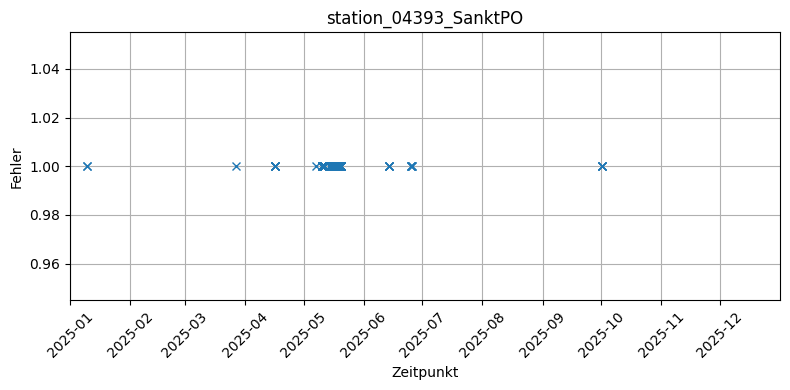

In [66]:
UTC.loc[negative_indices_ghi]
print(f"Fehlerwerte GHI: {len(negative_indices_ghi)}")
plt.figure(figsize=(8,4))
plt.plot(UTC.loc[negative_indices_ghi], [1]*len(negative_indices_ghi), linestyle="none", marker="x")
plt.xlim(start, ende)
plt.xticks(rotation=45)
plt.xlabel("Zeitpunkt")
plt.ylabel("Fehler")
plt.title(stationsID)
plt.grid(True)
plt.tight_layout()
plt.show()


In [67]:
new_row = ['', '', '', '', '','W/m2','W/m2','deg.C']   
# einheiten einfügen bei CSV -> entkommentieren der beiden Zeilen unten
# #df_15 = pd.concat([pd.DataFrame([new_row], columns=df_15.columns), df_15], ignore_index=True) # nur einmal einfügen
# Einheiten-Spalte nur einmal einfügen:
df_neu_relevant = pd.concat([pd.DataFrame([new_row], columns=df_neu_relevant.columns), df_neu_relevant], ignore_index=True) 
df_neu_relevant

,Year,Month,Day,Hour,Minute,GHI,DHI,Tamb
0,,,,,,W/m2,W/m2,deg.C
1,2025,1,1,0,26,0.0,0.0,6.7
2,2025,1,1,1,26,0.0,0.0,7.0
3,2025,1,1,2,26,0.0,0.0,7.5
4,2025,1,1,3,26,0.0,0.0,8.2
...,...,...,...,...,...,...,...,...
8756,2025,12,31,19,25,0.0,0.0,5.7
8757,2025,12,31,20,25,0.0,0.0,5.9
8758,2025,12,31,21,25,0.0,0.0,5.6
8759,2025,12,31,22,25,0.0,0.0,5.5


In [68]:
#achtung! name muss noch im cache sein!

# name_new_1 = name.replace('.csv', '_2024_1h_1_for_pv_syst.csv')
if save_as_file :
    from ntpath import join


    start_string = start.strftime("%Y-%m-%d")
    ende_string = ende.strftime("%Y-%m-%d") 

    csv_eding = 'for_pv_syst.csv'
    name_new_1 = ''.join([stationsID,"_",start_string,"_",ende_string,"_",timestep,'_1_',csv_eding])

    # nur ausführen wenn Datei ready ist, sonst wird bestehende Datei überschrieben 
    df_neu_relevant.to_csv(name_new_1, sep=';', index=False, header=['Year','Month','Day','Hour','Minute','GHI','DHI','Tamb'])


#   diese Header händisch hinzufügen

#Meteo hourly data;;;;;;;
#Description of Data Set e.g. DWD DataBase;;;;;;;
# GHI. DHI and Temp are retrieved. Set Time Zone to 0. since time stamp is in UTC!;;;;;;;
#Site; 00662_Braunschweig;;;;;;;
#Country; germany;;;;;;;
#Data Source; DWD_station_00662_Braunschweig;;;;;;;
#Time step; 1h;;;;;;;
#Year; 2024;;;;;;;
#Latitude; 52.2915;;;;;;;
#Longitude; 10.4464;;;;;;;
#Altitude; 81.44;;;;;;;
#Time Zone; 1  ;;;;;;;
#Time reference;UT;;;;;;
#Hour Shift;-1;;;;;;
#Time Shift;0;;;;;;

# --> muss aber individuell je nach Metadaten angepasst werden (könnte man aber in Zukunft automatisieren)

# Zielformat
# Year;Month;Day;Hour;Minute;GHI;Tamb;
# ;;;;;W/m2;deg.C;

In [69]:
"""
ToDo:

# location checken

# Simulieren mit Lima

# in Zukunft Interpolieren, wenn Werte fehlen!!! -> hat jetzt durch Zufall auch ohne funktioniert, aber kann man sich nicht 100%ig drauf verlassen

# Wetterstationen filtern später


Es reicht am Anfang #Time Reference; 1  zu ergänzen --> das müsste für PV-Syst dann klar stellen, dass es selbst den Shift von UTF 1 zu local time macht

https://www.pvsyst.com/help/meteo-database/notes-on-meteo/meteonote7-time-shift-in-meteo-files.html#time-shift-correction-when-importing-data 
If there is a time shift varying along the year:

With the general ASCII importing tool, consider using the DST correction (option "Summer Time > Apply").
Otherwise there is no practical way, except modifying the dates directly in the source file.
If the file is written in UT (Universal Time):

With the general ASCII importing tool, check the box "Universal time".
With PVsyst standard format, you can add a line #Time Reference with the value UT

"""

'\nToDo:\n\n# location checken\n\n# Simulieren mit Lima\n\n# in Zukunft Interpolieren, wenn Werte fehlen!!! -> hat jetzt durch Zufall auch ohne funktioniert, aber kann man sich nicht 100%ig drauf verlassen\n\n# Wetterstationen filtern später\n\n\nEs reicht am Anfang #Time Reference; 1  zu ergänzen --> das müsste für PV-Syst dann klar stellen, dass es selbst den Shift von UTF 1 zu local time macht\n\nhttps://www.pvsyst.com/help/meteo-database/notes-on-meteo/meteonote7-time-shift-in-meteo-files.html#time-shift-correction-when-importing-data \nIf there is a time shift varying along the year:\n\nWith the general ASCII importing tool, consider using the DST correction (option "Summer Time > Apply").\nOtherwise there is no practical way, except modifying the dates directly in the source file.\nIf the file is written in UT (Universal Time):\n\nWith the general ASCII importing tool, check the box "Universal time".\nWith PVsyst standard format, you can add a line #Time Reference with the value 